# TPDA Classification (Bivariate, 3 Classes) with Fenchel-Young Loss (TPDA Head + FY Module)

We generate a 3-class dataset with equal priors, where each class-conditional density is a bivariate truncated parabola:

$$
\hat p_c(t)=\left[-\tau_c-\frac12(t-\mu_c)^\top\Sigma_c^{-1}(t-\mu_c)\right]_+,
$$

$$
Q_c(t):=(t-\mu_c)^\top\Sigma_c^{-1}(t-\mu_c),
\qquad
\tau_c=-\left(\frac{\Gamma\!\left(\frac{N}{2}+2\right)}{\sqrt{(2\pi)^N\det(\Sigma_c)}}\right)^{\frac{2}{N+2}},\quad N=2.
$$

Now class priors are **trainable**: $\pi=\mathrm{softmax}(\rho)$, with $\sum_c \pi_c=1$.
For a labeled sample $(t_0,c_0)$, we optimize the attached joint FY loss:

$$
\ell_{\mathrm{joint}}(t_0,c_0)
=\frac12-\frac{2}{N+4}\sum_{c=1}^{K}\pi_c^2\tau_c
+\pi_{c_0}\left(\frac12Q_{c_0}(t_0)+\tau_{c_0}\right).
$$


This notebook reproduces the same experiment but imports `TPDAHead` and `tpda_joint_fy_loss` from `tpda_head_fy.py`.


Data setup note: classes 0 and 1 are configured to partially overlap in input space; class 2 is kept more separated.


In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import torch

from tpda_head_fy import TPDAHead, tpda_joint_fy_loss

np.random.seed(13)
torch.manual_seed(13)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)


device: cuda


In [2]:
def tau_from_cov(cov):
    # cov: (2, 2) SPD numpy array
    n = cov.shape[0]
    det_term = np.linalg.det(2.0 * np.pi * cov)
    numerator = math.gamma(n / 2.0 + 2.0)
    return - (numerator / np.sqrt(det_term)) ** (2.0 / (n + 2.0))


def density_bivariate_trunc_parabola(x, mu, cov):
    # x: (..., 2)
    inv_cov = np.linalg.inv(cov)
    delta = x - mu
    maha = np.einsum('...i,ij,...j->...', delta, inv_cov, delta)
    tau = tau_from_cov(cov)
    return np.maximum(-tau - 0.5 * maha, 0.0)


def support_radius_for_ball_envelope(cov):
    # Conservative Euclidean envelope from Mahalanobis support.
    tau = tau_from_cov(cov)
    inv_cov = np.linalg.inv(cov)
    lam_min = np.linalg.eigvalsh(inv_cov).min()
    return np.sqrt(2.0 * (-tau) / lam_min)


def sample_bivariate_trunc_parabola(mu, cov, n, batch_size=8192):
    tau = tau_from_cov(cov)
    fmax = -tau
    r = support_radius_for_ball_envelope(cov)

    out = []
    while len(out) < n:
        x = np.random.uniform(mu - r, mu + r, size=(batch_size, 2))
        y = np.random.uniform(0.0, fmax, size=batch_size)
        fx = density_bivariate_trunc_parabola(x, mu, cov)
        accepted = x[y <= fx]
        out.extend(accepted.tolist())

    return np.array(out[:n], dtype=np.float64)


In [3]:
# Generate 3-class data with equal priors (classes 0 and 1 partially overlap)
K = 3
N = 2
n_per_class = 1800

mu_true = np.array([
    [-0.9, -0.2],
    [ 0.6,  0.1],
    [ 2.8,  2.5],
], dtype=np.float64)

Sigma_true = np.array([
    [[1.10, 0.30], [0.30, 0.95]],
    [[1.05, -0.25], [-0.25, 0.90]],
    [[0.70, 0.08], [0.08, 0.65]],
], dtype=np.float64)

X_list = []
y_list = []
for k in range(K):
    Xk = sample_bivariate_trunc_parabola(mu_true[k], Sigma_true[k], n_per_class)
    yk = np.full(n_per_class, k, dtype=np.int64)
    X_list.append(Xk)
    y_list.append(yk)

X = np.vstack(X_list)
y = np.concatenate(y_list)

perm = np.random.permutation(len(X))
X = X[perm]
y = y[perm]

# Train/test split
n_train = int(0.8 * len(X))
X_train, y_train = X[:n_train], y[:n_train]
X_test, y_test = X[n_train:], y[n_train:]

print('Train shape:', X_train.shape, y_train.shape)
print('Test shape: ', X_test.shape, y_test.shape)
print('Class counts (train):', np.bincount(y_train, minlength=K))


Train shape: (4320, 2) (4320,)
Test shape:  (1080, 2) (1080,)
Class counts (train): [1420 1471 1429]


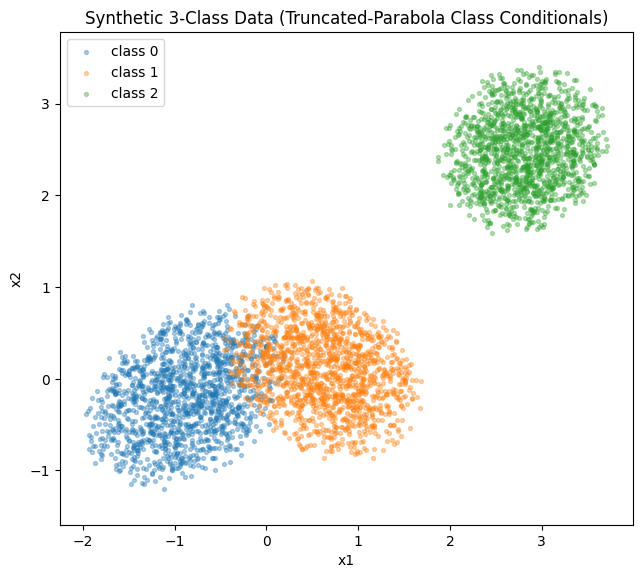

In [4]:
# Visualize generated data
colors = ['tab:blue', 'tab:orange', 'tab:green']

plt.figure(figsize=(7.4, 6.4))
for k in range(K):
    idx = (y_train == k)
    plt.scatter(X_train[idx, 0], X_train[idx, 1], s=8, alpha=0.35, color=colors[k], label=f'class {k}')

plt.title('Synthetic 3-Class Data (Truncated-Parabola Class Conditionals)')
plt.xlabel('x1')
plt.ylabel('x2')
plt.axis('equal')
plt.legend()
plt.show()


In [5]:
# Fenchel-Young (single-distribution form) is applied per example to its true class.
# We keep training objective explicit in terms of (mu_k, Sigma_k) instead of a multiclass sparsemax surrogate.


In [6]:
# Small neural network backbone + TPDA head
class SmallBackbone(torch.nn.Module):
    def __init__(self, in_dim=2, hidden_dim=32, out_dim=2):
        super().__init__()
        self.net = torch.nn.Sequential(
            torch.nn.Linear(in_dim, hidden_dim),
            torch.nn.ReLU(),
            torch.nn.Linear(hidden_dim, hidden_dim),
            torch.nn.ReLU(),
            torch.nn.Linear(hidden_dim, out_dim),
        )

    def forward(self, x):
        return self.net(x)


class TPDANet(torch.nn.Module):
    def __init__(self, num_classes, in_dim=2, hidden_dim=32, feature_dim=2):
        super().__init__()
        self.backbone = SmallBackbone(in_dim=in_dim, hidden_dim=hidden_dim, out_dim=feature_dim)
        self.head = TPDAHead(num_classes=num_classes, feature_dim=feature_dim)

    def forward(self, x):
        z = self.backbone(x)
        return self.head(z)

    def fy_loss(self, x, y):
        z = self.backbone(x)
        return tpda_joint_fy_loss(self.head, z, y)


In [7]:
# Fit small neural net + TPDA head with joint FY loss using mini-batches (CUDA if available)
Xtr = torch.tensor(X_train, dtype=torch.float32, device=device)
ytr = torch.tensor(y_train, dtype=torch.long, device=device)
Xte = torch.tensor(X_test, dtype=torch.float32, device=device)
yte = torch.tensor(y_test, dtype=torch.long, device=device)

batch_size = 256
num_epochs = 10

train_ds = torch.utils.data.TensorDataset(Xtr, ytr)
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=batch_size, shuffle=True, drop_last=False)

model = TPDANet(num_classes=K, in_dim=N, hidden_dim=32, feature_dim=2).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

loss_hist = []
train_acc_hist = []
test_acc_hist = []

for epoch in range(num_epochs):
    model.train()
    epoch_loss_sum = 0.0
    epoch_count = 0

    for xb, yb in train_loader:
        optimizer.zero_grad()
        loss = model.fy_loss(xb, yb).mean()
        loss.backward()
        optimizer.step()

        bs = xb.shape[0]
        epoch_loss_sum += float(loss.item()) * bs
        epoch_count += bs

    epoch_loss = epoch_loss_sum / max(epoch_count, 1)

    with torch.no_grad():
        model.eval()
        priors_eval = model.head.priors()
        scores_tr = model(Xtr)
        pred_tr = scores_tr.argmax(dim=1)
        train_acc = (pred_tr == ytr).float().mean().item()

        scores_te = model(Xte)
        pred_te = scores_te.argmax(dim=1)
        test_acc = (pred_te == yte).float().mean().item()

    loss_hist.append(epoch_loss)
    train_acc_hist.append(train_acc)
    test_acc_hist.append(test_acc)

    if epoch % 10 == 0:
        pi_np = priors_eval.detach().cpu().numpy()
        print(f"epoch {epoch:4d} | loss={epoch_loss:.5f} | train_acc={train_acc:.4f} | test_acc={test_acc:.4f} | pi={pi_np}")

with torch.no_grad():
    cov_hat = model.head.covariances().detach().cpu().numpy()
    mu_hat = model.head.mu.detach().cpu().numpy()
    pi_hat = model.head.priors().detach().cpu().numpy()

print("\nFitted TPDA means in learned feature space (mu_hat):\n", mu_hat)
print("\nFitted TPDA covariances in learned feature space (Sigma_hat):\n", cov_hat)
print("\nFitted priors (pi_hat):\n", pi_hat)
print(f"\nFinal train acc: {train_acc_hist[-1]:.4f}")
print(f"Final test  acc: {test_acc_hist[-1]:.4f}")


epoch    0 | loss=1.33127 | train_acc=0.5840 | test_acc=0.6167 | pi=[0.28456587 0.366611   0.34882316]

Fitted TPDA means in learned feature space (mu_hat):
 [[-1.2565455  -4.1388087 ]
 [-0.03086621 -1.7424276 ]
 [-3.6869483   0.27408087]]

Fitted TPDA covariances in learned feature space (Sigma_hat):
 [[[1.0001 0.    ]
  [0.     1.0001]]

 [[1.0001 0.    ]
  [0.     1.0001]]

 [[1.0001 0.    ]
  [0.     1.0001]]]

Fitted priors (pi_hat):
 [0.23197643 0.36794308 0.4000805 ]

Final train acc: 0.9699
Final test  acc: 0.9694


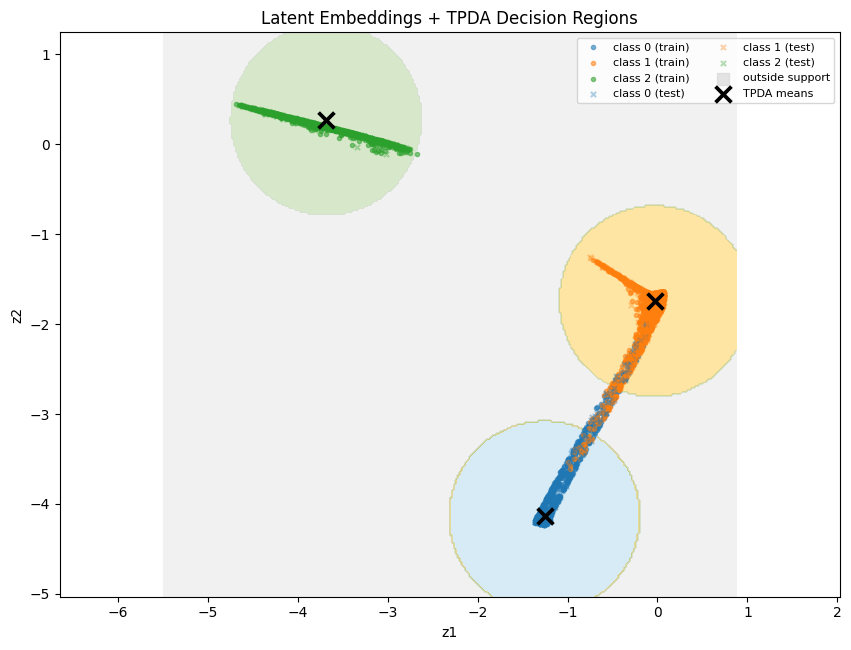

In [8]:
# Latent-space visualization in a single plot: embeddings + TPDA decision regions
import matplotlib.colors as mcolors

with torch.no_grad():
    model.eval()
    Xtr_t = torch.tensor(X_train, dtype=torch.float32, device=device)
    Xte_t = torch.tensor(X_test, dtype=torch.float32, device=device)
    z_tr = model.backbone(Xtr_t).detach().cpu().numpy()
    z_te = model.backbone(Xte_t).detach().cpu().numpy()

# Build latent grid from learned embeddings
z_all = np.vstack([z_tr, z_te])
z1_min, z1_max = z_all[:, 0].min() - 0.8, z_all[:, 0].max() + 0.8
z2_min, z2_max = z_all[:, 1].min() - 0.8, z_all[:, 1].max() + 0.8
zz1, zz2 = np.meshgrid(np.linspace(z1_min, z1_max, 300), np.linspace(z2_min, z2_max, 300))
z_grid_np = np.stack([zz1.ravel(), zz2.ravel()], axis=1)

with torch.no_grad():
    z_grid = torch.tensor(z_grid_np, dtype=torch.float32, device=device)
    scores_grid = model.head(z_grid)
    outside_mask = (scores_grid.max(dim=1).values <= 1e-10)
    pred_grid = scores_grid.argmax(dim=1)
    pred_grid[outside_mask] = K
    pred_grid = pred_grid.detach().cpu().numpy().reshape(zz1.shape)

region_colors = ['#8ecae6', '#ffb703', '#90be6d', '#d9d9d9']
cmap = mcolors.ListedColormap(region_colors[:K] + [region_colors[-1]])

plt.figure(figsize=(8.6, 6.6))
plt.contourf(zz1, zz2, pred_grid, levels=np.arange(-0.5, K + 1.5, 1), alpha=0.36, cmap=cmap)

# Overlay train embeddings
for k in range(K):
    idx = (y_train == k)
    plt.scatter(z_tr[idx, 0], z_tr[idx, 1], s=9, alpha=0.55, color=colors[k], label=f'class {k} (train)')

# Optional test overlay with x marker
for k in range(K):
    idx = (y_test == k)
    plt.scatter(z_te[idx, 0], z_te[idx, 1], s=14, alpha=0.35, color=colors[k], marker='x', label=f'class {k} (test)')

plt.scatter([], [], s=80, marker="s", color=region_colors[-1], alpha=0.7, label="outside support")
plt.scatter(mu_hat[:, 0], mu_hat[:, 1], c="black", s=130, marker="x", linewidths=2.7, label="TPDA means")
plt.title('Latent Embeddings + TPDA Decision Regions')
plt.xlabel('z1')
plt.ylabel('z2')
plt.axis('equal')
plt.legend(loc="best", fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig("TPDA_latent_space.png", dpi=600)
plt.show()


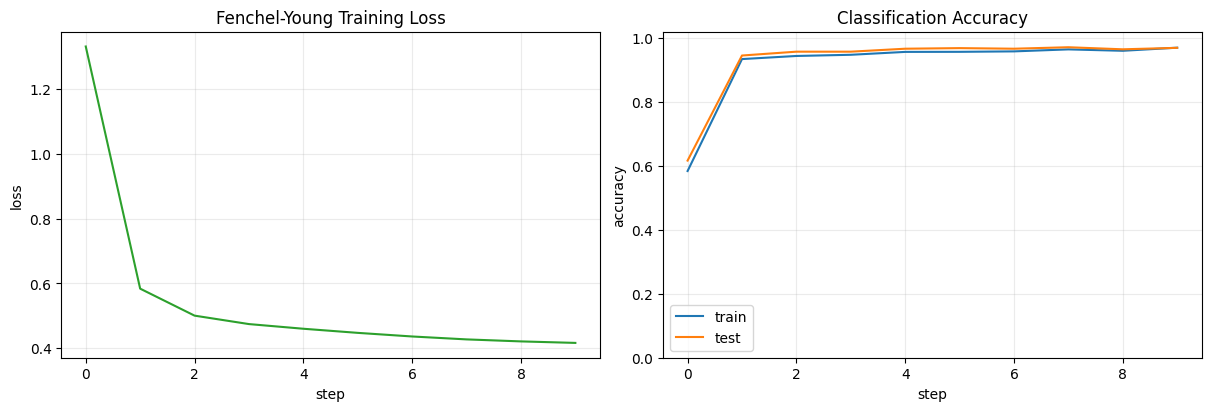

In [9]:
# Optimization curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

ax[0].plot(loss_hist, color='tab:green')
ax[0].set_title('Fenchel-Young Training Loss')
ax[0].set_xlabel('step')
ax[0].set_ylabel('loss')
ax[0].grid(alpha=0.25)

ax[1].plot(train_acc_hist, label='train', color='tab:blue')
ax[1].plot(test_acc_hist, label='test', color='tab:orange')
ax[1].set_title('Classification Accuracy')
ax[1].set_xlabel('step')
ax[1].set_ylabel('accuracy')
ax[1].set_ylim(0.0, 1.02)
ax[1].grid(alpha=0.25)
ax[1].legend()

plt.show()
